# 05 - Evaluation, Explainability and External Validation

**Goal:** Evaluate the selected model (random forest on log T, log L, log R, A_M) beyond a single accuracy number.

1. Final evaluation on the held-out test set (used once)
2. Error analysis on out-of-fold predictions
3. Confidence and calibration of the predicted probabilities
4. Feature importance
5. Human-readable rules from a shallow decision tree
6. External check on real, catalogued stars
7. Save artifacts for the app

## 1. Setup

In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.metrics import (accuracy_score, f1_score, log_loss, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
from sklearn.tree import DecisionTreeClassifier, export_text

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
ROOT = Path("..") if Path("../data").exists() else Path(".")
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

RAW = ["Temperature", "L", "R", "A_M"]
TYPE_NAMES = {0: "Red Dwarf", 1: "Brown Dwarf", 2: "White Dwarf",
              3: "Main Sequence", 4: "Super Giant", 5: "Hyper Giant"}
LABELS = [TYPE_NAMES[i] for i in range(6)]

clean = pd.read_csv(ROOT / "data" / "stars_clean.csv")
X, y = clean[RAW], clean["Type"]
# SAME split as the model-comparison notebook (same seed and stratification)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
model = joblib.load(ROOT / "models" / "star_classifier.joblib")
print("train:", X_train.shape, "test:", X_test.shape)

train: (192, 4) test: (48, 4)


## 2. Held-out test evaluation

The test set was not used for model comparison or tuning. This is the single final evaluation. With 48 stars, one error equals about 2.1 percentage points, so interpret it together with the cross-validation results.

In [2]:
pred = model.predict(X_test)
proba = model.predict_proba(X_test)

print(f"Accuracy : {accuracy_score(y_test, pred):.3f}")
print(f"Macro F1 : {f1_score(y_test, pred, average='macro'):.3f}")
print(f"Log loss : {log_loss(y_test, proba, labels=model.classes_):.3f}")
print(f"Errors   : {(pred != y_test).sum()} of {len(y_test)}\n")
print(classification_report(y_test, pred, target_names=LABELS, digits=3))

Accuracy : 1.000
Macro F1 : 1.000
Log loss : 0.015
Errors   : 0 of 48

               precision    recall  f1-score   support

    Red Dwarf      1.000     1.000     1.000         8
  Brown Dwarf      1.000     1.000     1.000         8
  White Dwarf      1.000     1.000     1.000         8
Main Sequence      1.000     1.000     1.000         8
  Super Giant      1.000     1.000     1.000         8
  Hyper Giant      1.000     1.000     1.000         8

     accuracy                          1.000        48
    macro avg      1.000     1.000     1.000        48
 weighted avg      1.000     1.000     1.000        48



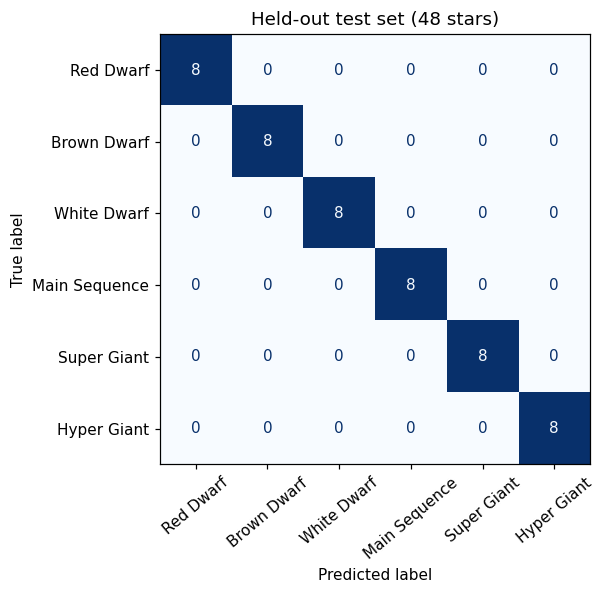

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=LABELS).plot(
    ax=ax, cmap="Blues", colorbar=False, xticks_rotation=40)
ax.set_title("Held-out test set (48 stars)"); ax.grid(False)
plt.tight_layout(); plt.savefig(FIG / "confusion_matrix_test.png", dpi=150); plt.show()

## 3. Error analysis on out-of-fold predictions

Test accuracy on 48 stars is a coarse estimate. To examine errors with more data, every training star is predicted by a model that never saw it (5-fold out-of-fold predictions).

In [4]:
cv = StratifiedKFold(5, shuffle=True, random_state=0)
oof_proba = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")
oof_pred = model.classes_[oof_proba.argmax(axis=1)]

print(f"Out-of-fold accuracy: {accuracy_score(y_train, oof_pred):.3f}")
errors = X_train.assign(true=y_train.map(TYPE_NAMES), predicted=pd.Series(oof_pred, index=X_train.index).map(TYPE_NAMES))
errors = errors[y_train != oof_pred]
print("Misclassified training stars:", len(errors))
errors

Out-of-fold accuracy: 1.000
Misclassified training stars: 0


,Temperature,L,R,A_M,true,predicted


## 4. Confidence and calibration

Even with perfect accuracy, the app shows probabilities, so they should be trustworthy. Two questions: which stars is the model least sure about, and does a stated 90% confidence mean 90% correct?

In [5]:
top_prob = oof_proba.max(axis=1)
conf = pd.DataFrame({"true": y_train.map(TYPE_NAMES).values,
                     "predicted": [TYPE_NAMES[c] for c in oof_pred],
                     "confidence": top_prob}, index=X_train.index)
print("Confidence by true class (out-of-fold):")
print(conf.groupby("true")["confidence"].agg(["mean", "min"]).round(3))
print("\nThe 8 least confident stars:")
X_train.join(conf).sort_values("confidence").head(8).round(3)

Confidence by true class (out-of-fold):
                mean    min
true                       
Brown Dwarf    0.966  0.767
Hyper Giant    0.990  0.910
Main Sequence  0.966  0.557
Red Dwarf      0.976  0.750
Super Giant    0.984  0.830
White Dwarf    0.994  0.880

The 8 least confident stars:


,Temperature,L,R,A_M,true,predicted,confidence
99,36108,198000.000,10.200,-4.400,Main Sequence,Main Sequence,0.557
92,4077,0.085,0.795,6.228,Main Sequence,Main Sequence,0.647
0,3068,0.002,0.170,16.120,Red Dwarf,Red Dwarf,0.750
78,2621,0.001,0.098,12.810,Brown Dwarf,Brown Dwarf,0.767
61,3432,0.001,0.190,16.940,Red Dwarf,Red Dwarf,0.813
195,3598,0.003,0.670,13.667,Brown Dwarf,Brown Dwarf,0.823
225,18734,224780.000,46.000,-7.450,Super Giant,Super Giant,0.830
104,11096,112000.000,12.000,-5.910,Super Giant,Super Giant,0.857


In [6]:
bins = np.array([0, 0.5, 0.7, 0.9, 1.0001])
idx = np.digitize(top_prob, bins) - 1
correct = (oof_pred == y_train.values)
rel = pd.DataFrame({"bin": [f"{bins[i]:.1f}-{min(bins[i+1],1):.1f}" for i in range(len(bins)-1)],
                    "n": [int((idx == i).sum()) for i in range(len(bins)-1)],
                    "mean confidence": [top_prob[idx == i].mean() if (idx == i).any() else np.nan for i in range(len(bins)-1)],
                    "accuracy": [correct[idx == i].mean() if (idx == i).any() else np.nan for i in range(len(bins)-1)]})
ece = sum(r.n / len(top_prob) * abs(r.accuracy - r["mean confidence"]) for _, r in rel.dropna().iterrows())
print(f"Expected calibration error (ECE): {ece:.3f}")
rel.round(3)

Expected calibration error (ECE): 0.021


,bin,n,mean confidence,accuracy
0,0.0-0.5,0,NaN,NaN
1,0.5-0.7,2,0.602,1.0
2,0.7-0.9,11,0.840,1.0
3,0.9-1.0,179,0.992,1.0


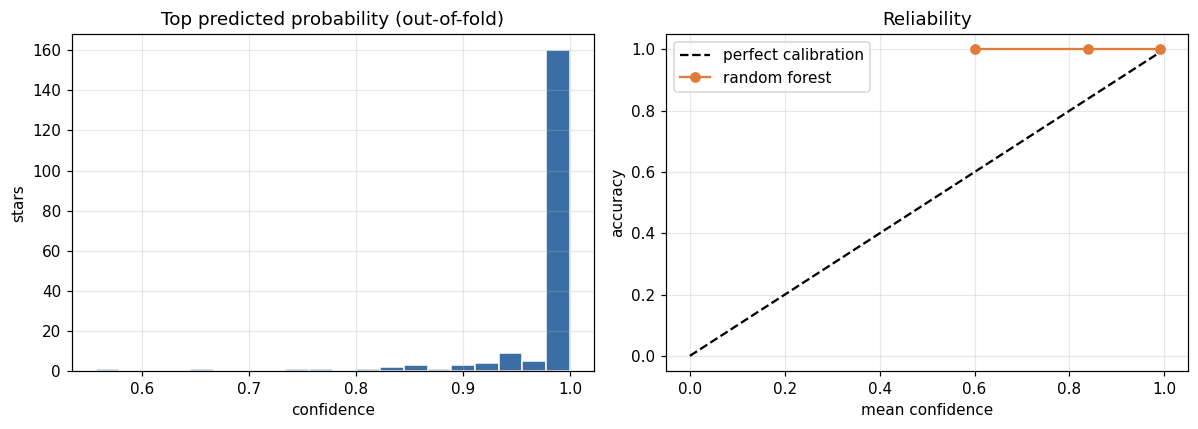

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(top_prob, bins=20, color="#3b6ea5", edgecolor="white")
axes[0].set(title="Top predicted probability (out-of-fold)", xlabel="confidence", ylabel="stars")
r = rel.dropna()
axes[1].plot([0, 1], [0, 1], "k--", label="perfect calibration")
axes[1].plot(r["mean confidence"], r["accuracy"], "o-", color="#e07b39", label="random forest")
axes[1].set(title="Reliability", xlabel="mean confidence", ylabel="accuracy"); axes[1].legend()
plt.tight_layout(); plt.savefig(FIG / "calibration.png", dpi=150); plt.show()

## 5. Feature importance

Two complementary views: the forest's built-in impurity importance, and **permutation importance** on the test set (how much does the *log loss* rise when one feature is shuffled?). Log loss is used because accuracy is saturated and would show no change.

In [8]:
FEATURES = ["log_Temperature", "log_L", "log_R", "A_M"]   # order produced by the pipeline's ColumnTransformer
impurity = pd.Series(model[-1].feature_importances_, index=FEATURES)

perm_ll = permutation_importance(model, X_test, y_test, scoring="neg_log_loss", n_repeats=50, random_state=0)
perm_acc = permutation_importance(model, X_test, y_test, scoring="accuracy", n_repeats=50, random_state=0)
imp = pd.DataFrame({"impurity importance": impurity.values,
                    "permutation: log-loss increase": perm_ll.importances_mean,
                    "  std": perm_ll.importances_std,
                    "permutation: accuracy drop": perm_acc.importances_mean}, index=FEATURES)
imp.round(3)

,impurity importance,permutation: log-loss increase,std,permutation: accuracy drop
log_Temperature,0.083,0.113,0.021,0.000
log_L,0.136,0.272,0.032,0.011
log_R,0.400,0.629,0.053,0.279
A_M,0.380,0.741,0.068,0.188


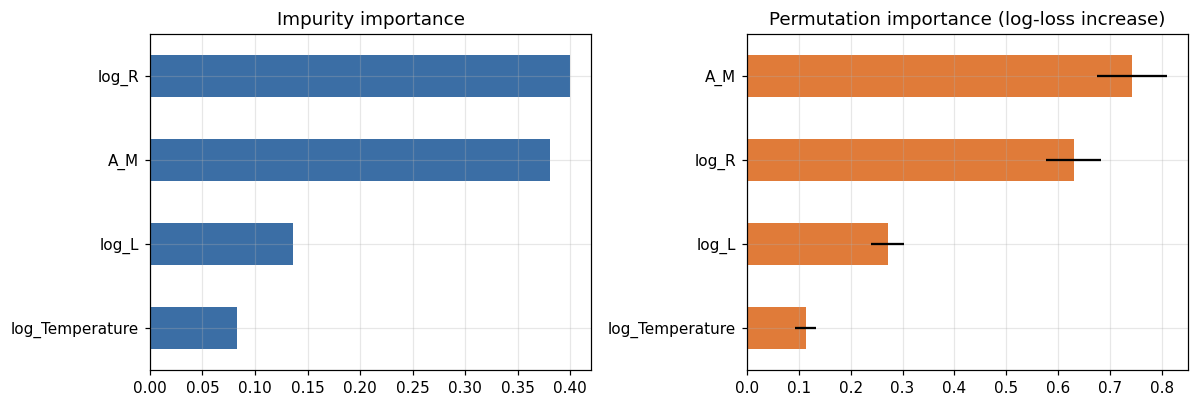

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
impurity.sort_values().plot.barh(ax=axes[0], color="#3b6ea5"); axes[0].set_title("Impurity importance")
pd.Series(perm_ll.importances_mean, index=FEATURES).sort_values().plot.barh(
    ax=axes[1], xerr=pd.Series(perm_ll.importances_std, index=FEATURES).reindex(
        pd.Series(perm_ll.importances_mean, index=FEATURES).sort_values().index), color="#e07b39")
axes[1].set_title("Permutation importance (log-loss increase)")
plt.tight_layout(); plt.savefig(FIG / "feature_importance.png", dpi=150); plt.show()

## 6. Human-readable rules (shallow decision tree)

A depth-4 decision tree is not the deployed model, but its rules show how simple the class boundaries are. This is a useful explanation for readers.

In [10]:
Xlog = pd.DataFrame({"log_Temperature": np.log10(X_train["Temperature"]), "log_L": np.log10(X_train["L"]),
                     "log_R": np.log10(X_train["R"]), "A_M": X_train["A_M"]})
tree = DecisionTreeClassifier(max_depth=4, random_state=42)
cv_acc = cross_val_score(tree, Xlog, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=0))
print(f"Depth-4 tree, 5-fold CV accuracy: {cv_acc.mean():.3f} +/- {cv_acc.std():.3f}\n")
tree.fit(Xlog, y_train)
print(export_text(tree, feature_names=list(Xlog.columns), class_names=LABELS))

Depth-4 tree, 5-fold CV accuracy: 0.890 +/- 0.089

|--- log_R <= -1.48
|   |--- class: White Dwarf
|--- log_R >  -1.48
|   |--- log_R <= -0.14
|   |   |--- A_M <= 15.49
|   |   |   |--- class: Brown Dwarf
|   |   |--- A_M >  15.49
|   |   |   |--- class: Red Dwarf
|   |--- log_R >  -0.14
|   |   |--- A_M <= -7.51
|   |   |   |--- class: Hyper Giant
|   |   |--- A_M >  -7.51
|   |   |   |--- log_R <= 1.04
|   |   |   |   |--- class: Main Sequence
|   |   |   |--- log_R >  1.04
|   |   |   |   |--- class: Super Giant



## 7. External check on real stars

The dataset is small and its luminosity values are not physically self-consistent (see the cleaning notes), so performance on it may not carry over to real stars. As an independent test, the model classifies well-known catalogued stars.

> **Verify before publishing.** The values below are approximate literature figures from memory; absolute magnitude is a mix of visual and bolometric conventions. Check each against SIMBAD or an astronomy reference and record the source. The expected type is the commonly accepted classification, mapped to this dataset's six classes.

In [11]:
real = pd.DataFrame([
    # name,               T (K),  L (Lo),   R (Ro),  A_M,   expected
    ("Sun",               5772,    1.0,      1.0,      4.83, 3),
    ("Vega",              9602,    40.1,     2.36,     0.58, 3),
    ("Sirius A",          9940,    25.4,     1.71,     1.43, 3),
    ("Proxima Centauri",  3042,    0.0017,   0.154,   15.60, 0),
    ("Barnard's Star",    3134,    0.0035,   0.196,   13.22, 0),
    ("Sirius B",         25200,    0.056,    0.0084,  11.18, 2),
    ("Procyon B",         7740,    0.00049,  0.0123,  13.0,  2),
    ("Rigel",            12100,    120000,   78.9,    -7.84, 4),
    ("Antares",           3660,    75900,    680,     -5.28, 4),
    ("Betelgeuse",        3600,    126000,   764,     -5.85, 4),
    ("VY Canis Majoris",  3490,    270000,   1420,    -8.0,  5),
], columns=["name", "Temperature", "L", "R", "A_M", "expected"])

p = model.predict_proba(real[RAW])
real["predicted"] = model.classes_[p.argmax(axis=1)]
real["confidence"] = p.max(axis=1)
real["match"] = real["predicted"] == real["expected"]
real["expected_code"] = real["expected"]          # keep numeric codes for the sensitivity check below
real["expected"] = real["expected"].map(TYPE_NAMES); real["predicted"] = real["predicted"].map(TYPE_NAMES)
print(f"Correct: {real['match'].sum()} of {len(real)}")
real[["name", "expected", "predicted", "confidence", "match"]].round(3)

Correct: 8 of 11


,name,expected,predicted,confidence,match
0,Sun,Main Sequence,Main Sequence,1.000,True
1,Vega,Main Sequence,Main Sequence,1.000,True
2,Sirius A,Main Sequence,Main Sequence,1.000,True
3,Proxima Centauri,Red Dwarf,Red Dwarf,0.910,True
4,Barnard's Star,Red Dwarf,Brown Dwarf,1.000,False
5,Sirius B,White Dwarf,White Dwarf,0.957,True
6,Procyon B,White Dwarf,White Dwarf,1.000,True
7,Rigel,Super Giant,Super Giant,0.530,True
8,Antares,Super Giant,Hyper Giant,0.533,False
9,Betelgeuse,Super Giant,Hyper Giant,0.533,False


In [12]:
# Are the real stars inside the range the model was trained on?
ranges = {c: (float(X_train[c].min()), float(X_train[c].max())) for c in RAW}
out = []
for _, row in real.iterrows():
    outside = [c for c in RAW if not (ranges[c][0] <= row[c] <= ranges[c][1])]
    out.append(", ".join(outside) if outside else "-")
real["outside training range"] = out
real[["name", "predicted", "match", "outside training range"]]

,name,predicted,match,outside training range
0,Sun,Main Sequence,True,-
1,Vega,Main Sequence,True,-
2,Sirius A,Main Sequence,True,-
3,Proxima Centauri,Red Dwarf,True,-
4,Barnard's Star,Brown Dwarf,False,-
5,Sirius B,White Dwarf,True,-
6,Procyon B,White Dwarf,True,-
7,Rigel,Super Giant,True,-
8,Antares,Hyper Giant,False,-
9,Betelgeuse,Hyper Giant,False,-


In [13]:
# Sensitivity: how much does the answer depend on the absolute-magnitude convention?
rows = []
for shift in [-1.0, -0.5, 0.0, 0.5, 1.0]:
    shifted = real[RAW].copy()
    shifted["A_M"] += shift
    predicted_codes = model.classes_[model.predict_proba(shifted).argmax(axis=1)]
    rows.append({"A_M shift (mag)": shift,
                 "correct": int((predicted_codes == real["expected_code"].values).sum())})
pd.DataFrame(rows)

,A_M shift (mag),correct
0,-1.0,7
1,-0.5,7
2,0.0,8
3,0.5,8
4,1.0,8


## 8. Save artifacts for the app

In [14]:
artifacts = {"features": RAW, "class_names": TYPE_NAMES,
             "training_ranges": {c: list(v) for c, v in ranges.items()}}
(ROOT / "models").mkdir(exist_ok=True)
with open(ROOT / "models" / "model_metadata.json", "w") as f:
    json.dump(artifacts, f, indent=2)
print(json.dumps(artifacts, indent=2))

{
  "features": [
    "Temperature",
    "L",
    "R",
    "A_M"
  ],
  "class_names": {
    "0": "Red Dwarf",
    "1": "Brown Dwarf",
    "2": "White Dwarf",
    "3": "Main Sequence",
    "4": "Super Giant",
    "5": "Hyper Giant"
  },
  "training_ranges": {
    "Temperature": [
      1939.0,
      40000.0
    ],
    "L": [
      8e-05,
      849420.0
    ],
    "R": [
      0.0084,
      1948.5
    ],
    "A_M": [
      -11.92,
      20.06
    ]
  }
}
